# 05 · Pre-registered analysis (H1–H4) and exploratory checks

Runs locally on the prediction files:
- `cache/biolingual/` from `03` (`recordings.csv`, `classes.json`, `probs_m3_P*.npy`, `probs_m4.npy`)
- `cache/cnn/` from `04` (`probs_m2.npy`, `recordings_m2.csv`, `classes.json`) — H1 and the M2 parts are skipped if absent

Hypotheses, tests and thresholds are exactly those in `PREREGISTRATION.md` (commit `bc2bc40`). Everything under **Exploratory** is not pre-registered.

Results → `outputs/analysis/`, figures → `figures/`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO / 'src'))
import analysis as A

OUT = REPO / 'outputs' / 'analysis'; OUT.mkdir(parents=True, exist_ok=True)
FIG = REPO / 'figures'; FIG.mkdir(exist_ok=True)

rec, sp, probs = A.load(REPO)
HAS_M2 = 'M2' in probs
y = rec['label_idx'].to_numpy()
print(len(rec), 'recordings |', len(sp), 'species | models:', list(probs))
results = {}

27642 recordings | 145 species | models: ['M3_P1', 'M3_P2', 'M3_P3', 'M4', 'M2']


## 0. Overall and by tertile

In [2]:
overall = A.summary(rec, probs).round(3)
overall.to_csv(OUT / 'overall.csv'); display(overall)

per_sp = {}
for name, P in probs.items():
    m = A.per_species(y, P.argmax(1), P.shape[1]); m.index = sp.index
    per_sp[name] = m
tert = pd.concat({k: v.assign(tertile=sp['tertile']).groupby('tertile')[['recall', 'f1']].mean()
                  for k, v in per_sp.items()}, axis=1).loc[['low', 'mid', 'high']].round(3)
display(tert)

,accuracy,macro_f1,macro_recall,top5
model,,,,
M3_P1,0.727,0.616,0.663,0.896
M3_P2,0.771,0.665,0.728,0.923
M3_P3,0.747,0.654,0.708,0.912
M4,0.798,0.726,0.712,0.927
M2,0.786,0.704,0.677,0.898


M3_P1         M3_P2         M3_P3            M4            M2       
        recall     f1 recall     f1 recall     f1 recall     f1 recall     f1
tertile                                                                      
low      0.567  0.432  0.663  0.459  0.654  0.486  0.574  0.612  0.502  0.571
mid      0.660  0.634  0.733  0.714  0.701  0.683  0.735  0.742  0.701  0.731
high     0.762  0.783  0.788  0.824  0.767  0.796  0.829  0.824  0.829  0.811

## H1 — supervised CNN (M2): F1 vs log(training recordings)

Supported if the 95% bootstrap CI of the `log(n_rec)` slope in the adjusted model excludes 0. Covariates are z-scored: recordings per recordist, mean duration, mean rating (rated recordings only), iNaturalist share.

In [3]:
if HAS_M2:
    simple, adjusted = A.h1(rec, sp, probs['M2'])
    print(A.fmt(simple, 'H1 simple  '))
    print(A.fmt(adjusted, 'H1 adjusted'))
    s_simple, s_adj = A.h1(rec, sp, probs['M2'], mask=(rec['n_secondary'] == 0).to_numpy())
    print(A.fmt(s_adj, 'H1 adjusted, no secondary labels (sensitivity)'))
    results['H1'] = {k: {kk: vv for kk, vv in r.items() if not kk.startswith('_')}
                     for k, r in [('simple', simple), ('adjusted', adjusted), ('adjusted_no_secondary', s_adj)]}
else:
    print('M2 predictions not found in cache/cnn — H1 skipped')

H1 simple  : n=145  rho=0.704 [0.590, 0.788]  slope=0.1185 [0.0857, 0.1508]  supported=yes
H1 adjusted: n=145  rho=0.704 [0.590, 0.788]  slope=0.1448 [0.0940, 0.1929]  supported=yes


H1 adjusted, no secondary labels (sensitivity): n=145  rho=0.704 [0.588, 0.787]  slope=0.1467 [0.0943, 0.1951]  supported=yes


## H2 — zero-shot (M3, P1): recall vs log(AnimalSpeak captions)

Primary on all recordings; confirmatory on `unseen` recordings (species with ≥ 5 unseen).

In [4]:
h2_all, h2_unseen = A.h2(rec, sp, probs['M3_P1'])
print(A.fmt(h2_all, 'H2 all recordings'))
print(A.fmt(h2_unseen, 'H2 unseen only    '))
no_sec = (rec['n_secondary'] == 0).to_numpy()
h2_ns = A.slope_test(*A.recall_vs_exposure(rec, sp, probs['M3_P1'], subset=no_sec))
print(A.fmt(h2_ns, 'H2 no secondary labels (sensitivity)'))
results['H2'] = {k: {kk: vv for kk, vv in r.items() if not kk.startswith('_')}
                 for k, r in [('all', h2_all), ('unseen', h2_unseen), ('no_secondary', h2_ns)]}

H2 all recordings: n=145  rho=0.387 [0.241, 0.517]  slope=0.0974 [0.0579, 0.1402]  supported=yes
H2 unseen only    : n=128  rho=0.378 [0.221, 0.533]  slope=0.1231 [0.0656, 0.1918]  supported=yes


H2 no secondary labels (sensitivity): n=145  rho=0.385 [0.239, 0.508]  slope=0.0951 [0.0561, 0.1391]  supported=yes


## H3 — is the slope steeper for zero-shot (M3) than for the linear probe (M4)?

Same audio embeddings, same x (log AnimalSpeak captions), per-species recall. Paired bootstrap over species of slope(M3) − slope(M4); supported if the CI excludes 0 on the positive side.

In [5]:
def show_h3(r, label):
    print(f"{label}: n={r['n_species']}  slope M3={r['slope_zero']:.4f}  M4={r['slope_probe']:.4f}  "
          f"diff={r['diff']:.4f} [{r['diff_ci'][0]:.4f}, {r['diff_ci'][1]:.4f}]  supported={'yes' if r['supported'] else 'no'}")
h3_all = A.h3(rec, sp, probs['M3_P1'], probs['M4'])
h3_unseen = A.h3(rec, sp, probs['M3_P1'], probs['M4'], subset=(rec['leak'] == 'unseen').to_numpy(), min_support=5)
show_h3(h3_all, 'H3 all recordings')
show_h3(h3_unseen, 'H3 unseen only    ')
results['H3'] = {'all': h3_all, 'unseen': h3_unseen}

H3 all recordings: n=145  slope M3=0.0974  M4=0.1392  diff=-0.0418 [-0.0840, 0.0030]  supported=no
H3 unseen only    : n=128  slope M3=0.1231  M4=0.1209  diff=0.0022 [-0.0546, 0.0653]  supported=no


## H4 — detection probability over k survey recordings, by tertile

`1 − (1 − recall)^k`, mean over the species in each tertile (descriptive). Assumes independent recordings; focal recordings, so an optimistic upper bound.

In [6]:
h4 = {}
for name in (['M2'] if HAS_M2 else []) + ['M3_P1', 'M4']:
    curves, _ = A.h4(rec, sp, probs[name])
    h4[name] = curves
    piv = curves.pivot(index='k', columns='tertile', values='mean')[['low', 'mid', 'high']]
    print(name, '— mean detection probability at k = 1, 3, 5, 10'); display(piv.loc[[1, 3, 5, 10]].round(3))
pd.concat(h4, names=['model']).to_csv(OUT / 'h4_detection.csv')

M2 — mean detection probability at k = 1, 3, 5, 10


tertile,low,mid,high
k,,,
1,0.502,0.701,0.829
3,0.807,0.959,0.993
5,0.888,0.991,1.000
10,0.936,1.000,1.000


M3_P1 — mean detection probability at k = 1, 3, 5, 10


tertile,low,mid,high
k,,,
1,0.567,0.660,0.762
3,0.824,0.900,0.964
5,0.889,0.944,0.989
10,0.938,0.968,0.999


M4 — mean detection probability at k = 1, 3, 5, 10


tertile,low,mid,high
k,,,
1,0.574,0.735,0.829
3,0.882,0.973,0.993
5,0.947,0.996,1.000
10,0.974,1.000,1.000


## Exploratory (not pre-registered)

### E1. Prompt sensitivity: does |recall(P1) − recall(P2)| shrink with exposure?
### E2. H2/H3 with the scientific-name prompt (P2)
### E3. Where do errors go? (share of errors landing on high-tertile species, vs chance)
### E4. Within-species seen vs unseen recall drop, M3 vs M4

In [7]:
e1 = A.prompt_sensitivity(rec, sp, probs['M3_P1'], probs['M3_P2'])
print(A.fmt(e1, 'E1 |P1-P2| vs exposure').replace('supported=yes', '').replace('supported=no', ''))

e2_h2, _ = A.h2(rec, sp, probs['M3_P2'])
e2_h3 = A.h3(rec, sp, probs['M3_P2'], probs['M4'])
print(A.fmt(e2_h2, 'E2 H2 with P2').rsplit('supported', 1)[0]); show_h3(e2_h3, 'E2 H3 with P2')

flows = pd.concat({n: A.confusion_flow(rec, sp, probs[n]) for n in probs if n in ('M2', 'M3_P1', 'M4')})
display(flows.round(3))

def seen_unseen_drop(P, min_n=5):
    rows = []
    for c in range(P.shape[1]):
        r = rec[y == c]; ok = P[y == c].argmax(1) == c
        s, u = ok[(r['leak'] == 'seen').to_numpy()], ok[(r['leak'] == 'unseen').to_numpy()]
        if len(s) >= min_n and len(u) >= min_n:
            rows.append(s.mean() - u.mean())
    return np.array(rows)
d3, d4 = seen_unseen_drop(probs['M3_P1']), seen_unseen_drop(probs['M4'])
rng = np.random.default_rng(0)
boot = [np.mean((d3 - d4)[rng.choice(len(d3), len(d3))]) for _ in range(A.N_BOOT)]
print(f'E4 within-species seen-unseen recall drop: M3 {d3.mean():.3f}, M4 {d4.mean():.3f}, '
      f'difference {np.mean(d3 - d4):.3f} [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}] (n={len(d3)} species)')
results['exploratory'] = dict(E1=e1, E2_H2=e2_h2, E2_H3=e2_h3, E4=dict(n=len(d3), m3=d3.mean(), m4=d4.mean(),
                              diff=np.mean(d3 - d4), ci=(np.percentile(boot, 2.5), np.percentile(boot, 97.5))))
flows.to_csv(OUT / 'confusion_flow.csv')

E1 |P1-P2| vs exposure: n=145  rho=-0.438 [-0.555, -0.297]  slope=-0.0982 [-0.1328, -0.0633]  


E2 H2 with P2: n=145  rho=0.238 [0.078, 0.397]  slope=0.0641 [0.0211, 0.1085]  
E2 H3 with P2: n=145  slope M3=0.0641  M4=0.1392  diff=-0.0751 [-0.1124, -0.0334]  supported=no


n_errors  to_high  to_high_chance  same_genus
      true_tertile                                               
M3_P1 low               1091    0.311           0.340       0.095
      mid               2099    0.343           0.340       0.073
      high              4368    0.396           0.333       0.044
M4    low                955    0.526           0.340       0.086
      mid               1585    0.573           0.340       0.050
      high              3047    0.635           0.333       0.038
M2    low               1136    0.659           0.340       0.052
      mid               1799    0.712           0.340       0.018
      high              2974    0.717           0.333       0.021

E4 within-species seen-unseen recall drop: M3 0.105, M4 0.104, difference 0.001 [-0.025, 0.025] (n=128 species)


## Save tables

In [8]:
table = sp[['scientific_name', 'common_name', 'n_rec', 'n_author', 'as_n_total', 'tertile', 'leak_unseen']].copy()
for name, m in per_sp.items():
    table[f'{name}_recall'] = m['recall'].round(4); table[f'{name}_f1'] = m['f1'].round(4)
for name in (['M2'] if HAS_M2 else []) + ['M3_P1']:
    ci = A.species_bootstrap_ci(rec, probs[name]); ci.index = sp.index
    table = table.join(ci.add_prefix(f'{name}_').round(4))
table.to_csv(OUT / 'per_species.csv')

def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items() if not str(k).startswith('_')}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer, np.bool_)): return o.item()
    return o
(OUT / 'results.json').write_text(json.dumps(clean(results), indent=2))
print('saved', sorted(p.name for p in OUT.iterdir()))

saved ['confusion_flow.csv', 'h4_detection.csv', 'overall.csv', 'per_species.csv', 'results.json']


## Figures

Colours follow the model everywhere: M2 blue, M3 orange, M4 aqua (first three slots of the validated categorical palette; all pairs pass for scatter). Tertiles use one ordinal blue ramp (validated with `--ordinal`).

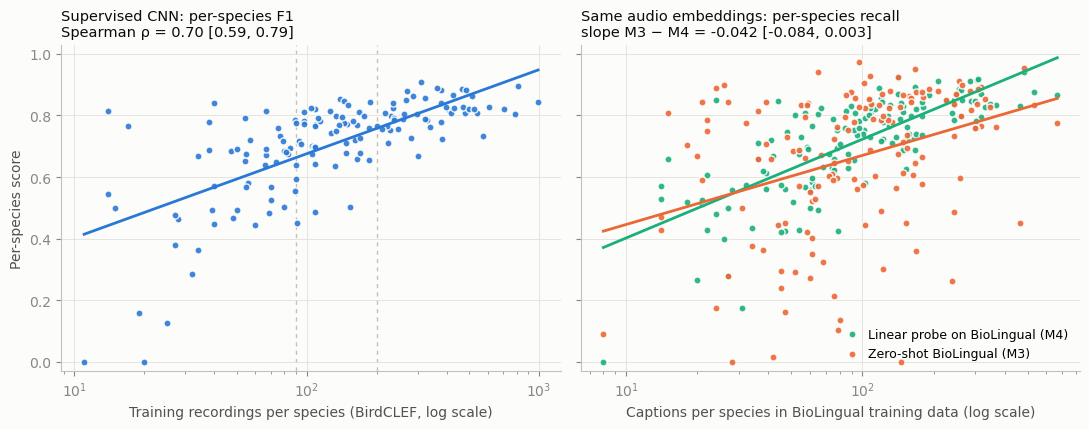

In [9]:
INK, INK2, MUTED, GRID, AXIS, SURF = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
COL = {'M2': '#2a78d6', 'M3_P1': '#eb6834', 'M4': '#1baf7a'}
NAME = {'M2': 'CNN (M2)', 'M3_P1': 'Zero-shot BioLingual (M3)', 'M4': 'Linear probe on BioLingual (M4)'}
TERT = {'low': '#5598e7', 'mid': '#256abf', 'high': '#104281'}
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.titlecolor': INK, 'figure.facecolor': SURF, 'axes.facecolor': SURF,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.6, 'legend.frameon': False})

def scatter_fit(ax, x, yv, color, label, label_y_offset=0.0):
    ax.scatter(x, yv, s=26, color=color, edgecolor=SURF, linewidth=1.0, alpha=0.9, zorder=3, label=label)
    b0, b1 = A.ols(yv, np.log(x))
    xs = np.linspace(np.log(x).min(), np.log(x).max(), 50)
    ax.plot(np.exp(xs), b0 + b1 * xs, color=color, lw=2, zorder=4)
    return b0 + b1 * xs[-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
ax = axes[0]
if HAS_M2:
    scatter_fit(ax, sp['n_rec'].to_numpy(), per_sp['M2']['f1'].to_numpy(), COL['M2'], NAME['M2'])
    r = results['H1']['simple']
    ax.set_title(f"Supervised CNN: per-species F1\nSpearman ρ = {r['rho']:.2f} [{r['rho_ci'][0]:.2f}, {r['rho_ci'][1]:.2f}]",
                 loc='left', fontsize=10.5)
else:
    ax.text(0.5, 0.5, 'M2 not available yet', transform=ax.transAxes, ha='center', color=MUTED)
for edge in [sp.loc[sp.tertile == 'mid', 'n_rec'].min(), sp.loc[sp.tertile == 'high', 'n_rec'].min()]:
    ax.axvline(edge, color=AXIS, lw=1, ls=(0, (3, 3)), zorder=1)
ax.set_xscale('log'); ax.set_xlabel('Training recordings per species (BirdCLEF, log scale)'); ax.set_ylabel('Per-species score')
ax.set_ylim(-0.03, 1.03)

ax = axes[1]
x_as = sp['as_n_total'].to_numpy()
for name, key in [('M4', 'M4'), ('M3_P1', 'M3_P1')]:
    end = scatter_fit(ax, x_as, per_sp[name]['recall'].to_numpy(), COL[key], NAME[key])
ax.set_xscale('log'); ax.set_xlabel('Captions per species in BioLingual training data (log scale)')
r3 = results['H3']['all']
ax.set_title(f"Same audio embeddings: per-species recall\nslope M3 − M4 = {r3['diff']:.3f} [{r3['diff_ci'][0]:.3f}, {r3['diff_ci'][1]:.3f}]",
             loc='left', fontsize=10.5)
ax.legend(loc='lower right', fontsize=9, handletextpad=0.3)
fig.tight_layout(); fig.savefig(FIG / 'fig1_disparity.png', dpi=200); plt.show()

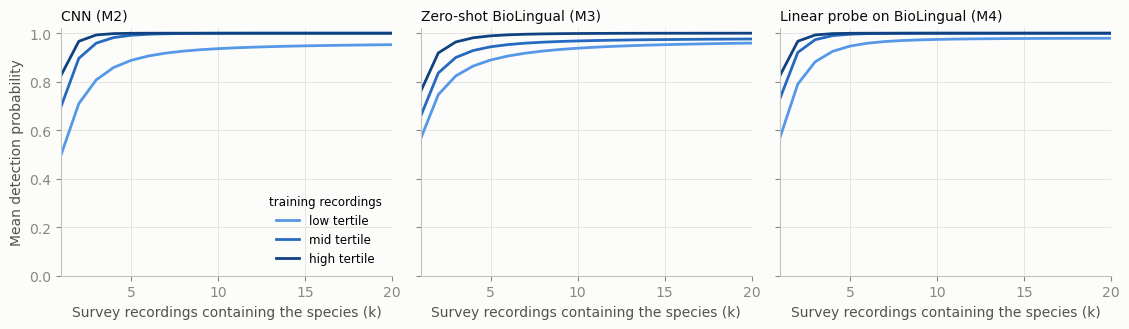

In [10]:
models = list(h4)
fig, axes = plt.subplots(1, len(models), figsize=(3.8 * len(models), 3.4), sharey=True)
for ax, name in zip(np.atleast_1d(axes), models):
    piv = h4[name].pivot(index='k', columns='tertile', values='mean')
    for t in ['low', 'mid', 'high']:
        ax.plot(piv.index, piv[t], color=TERT[t], lw=2, label=f'{t} tertile')
    ax.set_title(NAME[name], loc='left', fontsize=10); ax.set_xlabel('Survey recordings containing the species (k)')
    ax.set_xlim(1, 20)
np.atleast_1d(axes)[0].set_ylabel('Mean detection probability'); np.atleast_1d(axes)[0].set_ylim(0, 1.02)
np.atleast_1d(axes)[0].legend(loc='lower right', fontsize=8.5, title='training recordings', title_fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / 'fig2_detection.png', dpi=200); plt.show()